# Every colour option, with its name

**Shows:** each named set of colours as a strip. Top band: the ramps, then the diverging, cyclic and
categorical schemes. Second band: the sequential schemes. Last three bands: Wada's combinations, kept as a backup.

**Graph type:** swatch chart (`lf.swatches`).

**Writes:** `colours.svg` next to this notebook.

**How to use a name from the chart:** a scheme name goes to `lf.use(series=...)`; a ramp or scheme name
goes to `ramp=` in `lf.heatmap` and `lf.ramp`, and to `gradient=` in `lf.paths`.

**To tweak:** change the capitalised settings at the top of a cell and re-run from that cell down.

**Runs on:** the default `python3` kernel: Python 3.10 or newer with labfigs installed.

**To run it all:** `jupyter nbconvert --to notebook --execute --inplace colours.ipynb`, which also saves the figures in this notebook.

In [1]:
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

import labfigs as lf

lf.use()

## What goes in each column

- `ACROSS`: number of columns in every band
- `STOPS`: number of colours drawn for a smooth ramp

`bands` is a list of bands; each band is a list of `(title, {name: colours})`, one per column.

In [2]:
ACROSS, STOPS = 4, 64


def smooth(colours):
    return LinearSegmentedColormap.from_list("", colours)(np.linspace(0, 1, STOPS))


def split(title, sets):
    keys, size = list(sets), -(-len(sets) // ACROSS)
    return [(title if i == 0 else "", {key: sets[key] for key in keys[i * size:(i + 1) * size]}) for i in range(ACROSS)]


wada = lf.combos(kind="combination")
bands = [
    [("Ramps", {name: lf.ramp(STOPS, name) for name in lf.RAMPS}),
     ("Diverging", {"DIVERGING": lf.DIVERGING(np.linspace(0, 1, STOPS))} | {
         key: smooth(colours) for key, colours in lf.combos(kind="diverging").items()}),
     ("Cyclic", {key: smooth(colours) for key, colours in lf.combos(kind="cyclic").items()}),
     ("Categorical", {"CYCLE": lf.CYCLE} | lf.combos(kind="categorical"))],
    split("Sequential", {key: lf.ramp(STOPS, colours) for key, colours in lf.combos(kind="sequential").items()}),
    *(split(f"Backup: Wada, {title} colours", {key: colours for key, colours in wada.items() if len(colours) == size})
      for size, title in ((2, "two"), (3, "three"), (4, "four"))),
]
rows = [max(len(sets) for _, sets in band) for band in bands]

## Figure

Settings at the top of the cell:

- `NAME`: file name of the figure, without `.svg`
- `WIDTH`: figure width in inches
- `COLUMN_ASPECT`: height of an average column divided by its width; raise it for thicker strips

PosixPath('colours.svg')

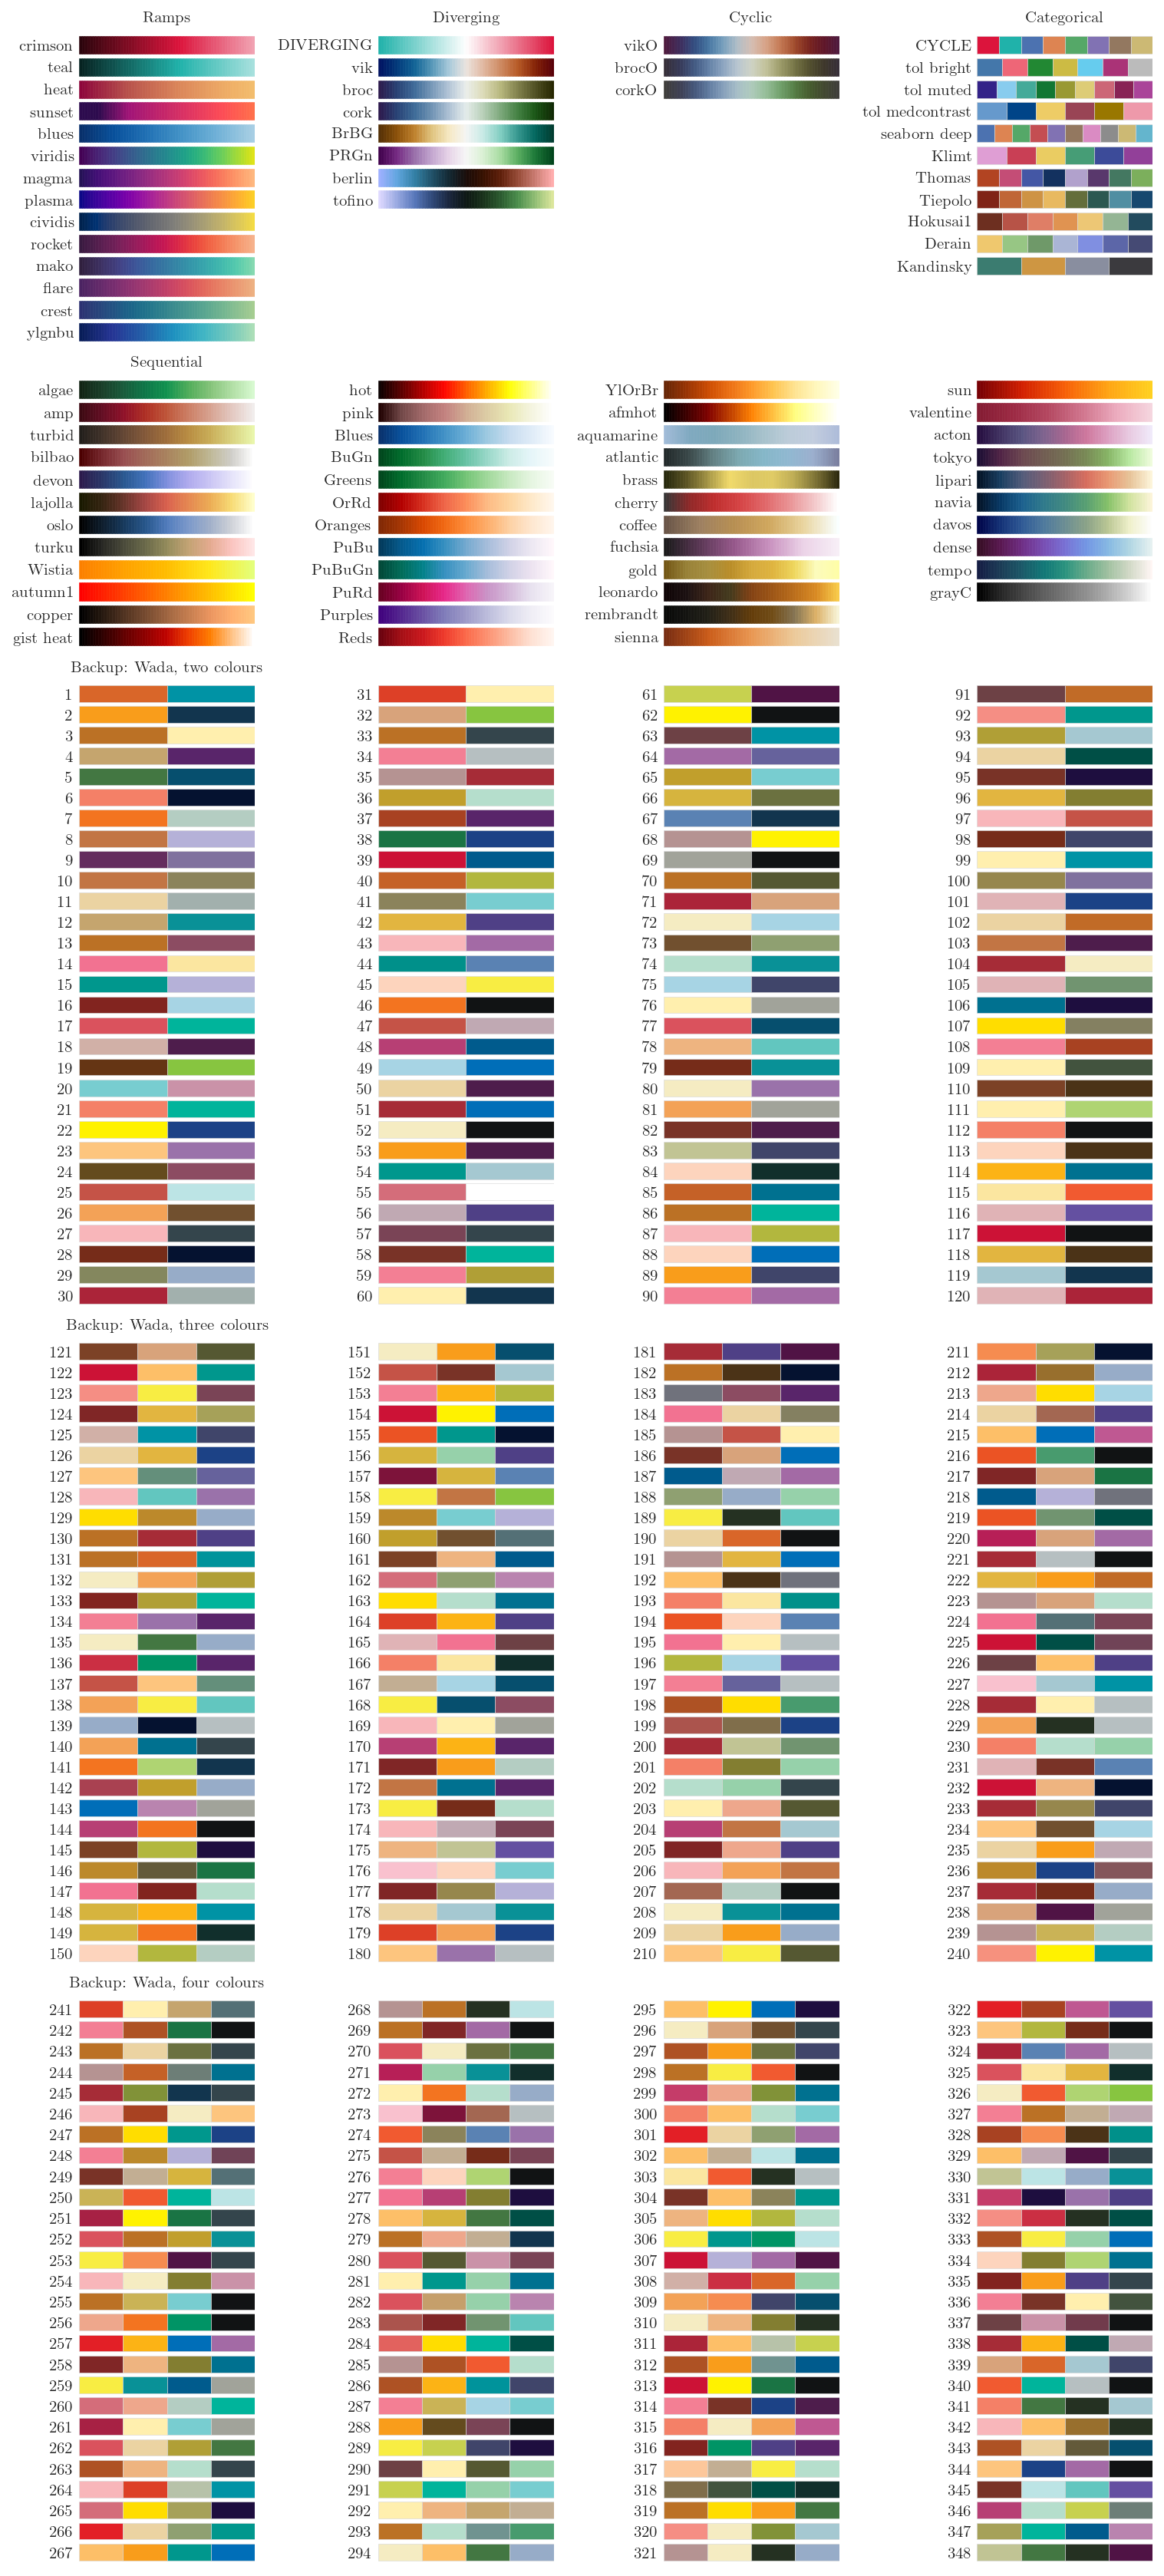

In [3]:
NAME = "colours"
WIDTH = 10
COLUMN_ASPECT = 1.6

fig, axes = lf.subplots(len(bands), ACROSS, width=WIDTH, aspect=COLUMN_ASPECT,
                        gridspec_kw={"height_ratios": [n + 2 for n in rows], "wspace": 0.08})
for line, band, n in zip(axes, bands, rows):
    for ax, (title, sets) in zip(line, band):
        lf.swatches(ax, sets)
        ax.set(title=title, ylim=(n - 0.4, -0.6))
lf.save(fig, NAME, trim=False)

## Checks

Fails if a scheme in the library is missing from the chart or shown twice. Nothing to tweak.

In [4]:
shown = [key for band in bands for _, sets in band for key in sets]
assert len(shown) == len(set(shown)) == len(lf.COMBOS) + len(lf.RAMPS) + 2, len(shown)
assert set(lf.COMBOS) | set(lf.RAMPS) <= set(shown) and lf.vividness(["yellow"]) == 1 > lf.vividness([lf.CRIMSON]) > lf.vividness([lf.TEAL])
assert lf.vividness(lf.CYCLE[2:]) < 0.6 and len(lf.combos()) == len(lf.COMBOS) > len(lf.combos(arc=(0, 60))) > 100